In [25]:
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

print("Current working directory:", Path.cwd())

Current working directory: c:\Users\hunte\VS Code\Visual Product Similarity\notebooks


In [2]:
import pandas as pd

current_path = Path.cwd()
project_root = current_path.parent

dataset_root = (
    project_root
    / "data"
    / "Raw"
    / "Stanford_Online_Products"
)

train_metadata_path = dataset_root / "Ebay_train.txt"

print("Project root:", project_root)
print("Dataset root:", dataset_root)
print("Train metadata exists:", train_metadata_path.exists())

Project root: c:\Users\hunte\VS Code\Visual Product Similarity
Dataset root: c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products
Train metadata exists: True


In [3]:
train_metadata = pd.read_csv(
    train_metadata_path,
    sep=r"\s+"
)

train_metadata.head()

,image_id,class_id,super_class_id,path
0,1,1,1,bicycle_final/111085122871_0.JPG
1,2,1,1,bicycle_final/111085122871_1.JPG
2,3,1,1,bicycle_final/111085122871_2.JPG
3,4,1,1,bicycle_final/111085122871_3.JPG
4,5,1,1,bicycle_final/111085122871_4.JPG


In [4]:
print("Shape:", train_metadata.shape)

train_metadata.info()

Shape: (59551, 4)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 59551 entries, 0 to 59550
Data columns (total 4 columns):
 #   Column          Non-Null Count  Dtype 
---  ------          --------------  ----- 
 0   image_id        59551 non-null  int64 
 1   class_id        59551 non-null  int64 
 2   super_class_id  59551 non-null  int64 
 3   path            59551 non-null  object
dtypes: int64(3), object(1)
memory usage: 1.8+ MB


In [5]:
print("Total rows:", len(train_metadata))
print("Unique image IDs:", train_metadata["image_id"].nunique())
print("Duplicate image IDs:", train_metadata["image_id"].duplicated().sum())

Total rows: 59551
Unique image IDs: 59551
Duplicate image IDs: 0


In [6]:
print("Unique product classes:", train_metadata["class_id"].nunique())
print("Unique broad categories:", train_metadata["super_class_id"].nunique())

Unique product classes: 11318
Unique broad categories: 12


In [8]:
images_per_class = (train_metadata.groupby('class_id').size())

print(images_per_class.describe())

count    11318.000000
mean         5.261619
std          2.978530
min          2.000000
25%          3.000000
50%          4.000000
75%          7.000000
max         12.000000
dtype: float64


In [9]:
category_distribution = (
    train_metadata
    .groupby("super_class_id")
    .agg(
        image_count=("image_id", "count"),
        product_classes=("class_id", "nunique")
    )
    .reset_index()
)

category_distribution

,super_class_id,image_count,product_classes
0,1,4168,574
1,2,5848,988
2,3,5845,1107
3,4,4985,911
4,5,2993,550
5,6,5013,949
6,7,6304,1108
7,8,6731,1321
8,9,3472,802
9,10,4367,894


In [16]:
train_metadata["category_name"] = (
    train_metadata["path"]
    .str.split("/")
    .str[0]
    .str.replace("_final", "", regex=False)
)

train_metadata.head()

,image_id,class_id,super_class_id,path,category_name
0,1,1,1,bicycle_final/111085122871_0.JPG,bicycle
1,2,1,1,bicycle_final/111085122871_1.JPG,bicycle
2,3,1,1,bicycle_final/111085122871_2.JPG,bicycle
3,4,1,1,bicycle_final/111085122871_3.JPG,bicycle
4,5,1,1,bicycle_final/111085122871_4.JPG,bicycle


In [17]:
category_distribution = (
    train_metadata
    .groupby(["super_class_id", "category_name"])
    .agg(
        image_count=("image_id", "count"),
        product_classes=("class_id", "nunique")
    )
    .reset_index()
)

category_distribution

,super_class_id,category_name,image_count,product_classes
0,1,bicycle,4168,574
1,2,cabinet,5848,988
2,3,chair,5845,1107
3,4,coffee_maker,4985,911
4,5,fan,2993,550
5,6,kettle,5013,949
6,7,lamp,6304,1108
7,8,mug,6731,1321
8,9,sofa,3472,802
9,10,stapler,4367,894


In [19]:
first_relative_path = train_metadata.loc[0, "path"]
first_full_path = dataset_root / first_relative_path

print("Relative path:", first_relative_path)
print("Full path:", first_full_path)
print("Image exists:", first_full_path.exists())

Relative path: bicycle_final/111085122871_0.JPG
Full path: c:\Users\hunte\VS Code\Visual Product Similarity\data\Raw\Stanford_Online_Products\bicycle_final\111085122871_0.JPG
Image exists: True


In [20]:
train_metadata["full_path"] = train_metadata["path"].apply(
    lambda relative_path: dataset_root / relative_path
)

train_metadata["image_exists"] = train_metadata["full_path"].apply(
    lambda image_path: image_path.exists()
)

print("Total metadata rows:", len(train_metadata))
print("Existing images:", train_metadata["image_exists"].sum())
print("Missing images:", (~train_metadata["image_exists"]).sum())

Total metadata rows: 59551
Existing images: 59551
Missing images: 0


In [22]:
sample_paths = train_metadata["full_path"].head(10)

for image_path in sample_paths:
    with Image.open(image_path) as image:
        print(
            image_path.name,
            "| Format:", image.format,
            "| Size:", image.size,
            "| Mode:", image.mode
        )

111085122871_0.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_1.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_2.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_3.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_4.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_5.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_6.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111085122871_7.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111265328556_0.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB
111265328556_1.JPG | Format: JPEG | Size: (400, 268) | Mode: RGB


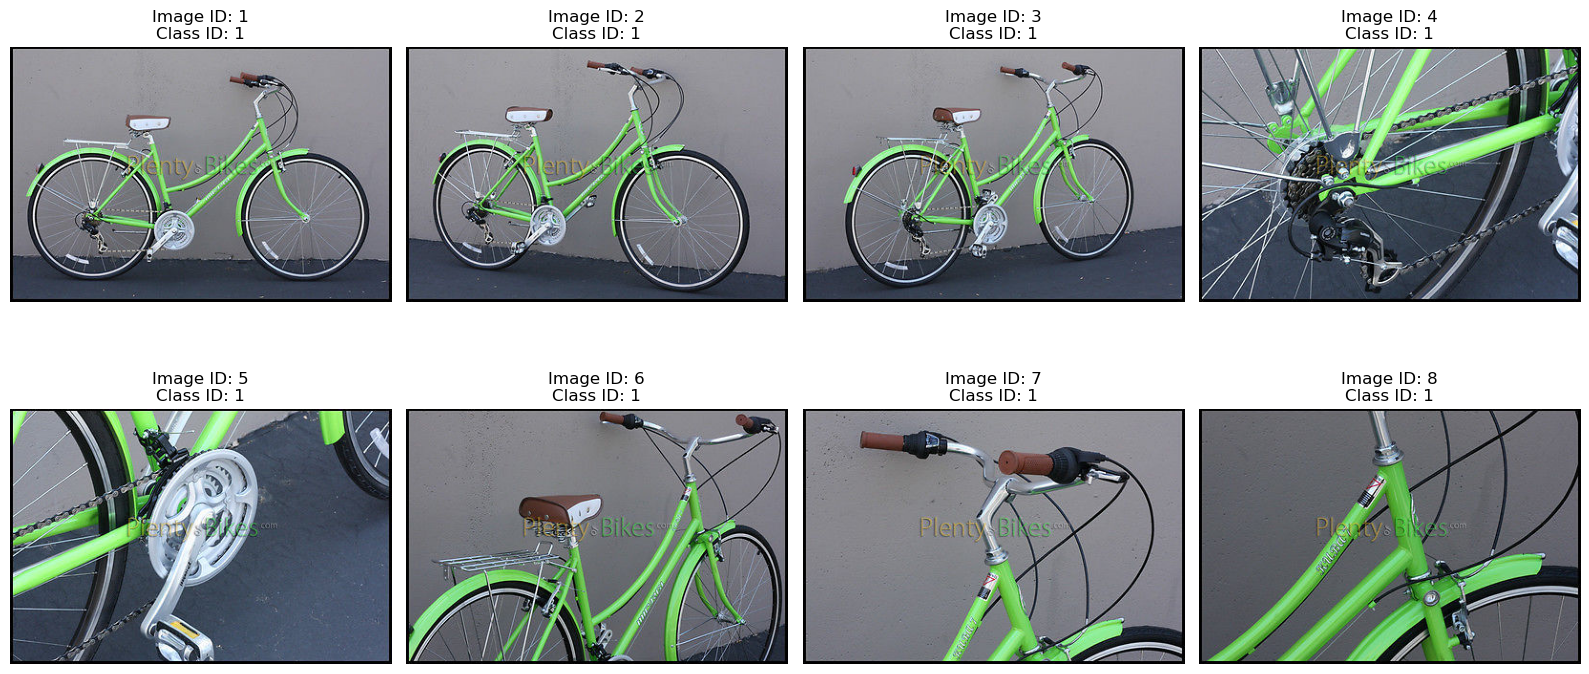

In [ ]:
sample_class_id = train_metadata.loc[0, "class_id"]

same_product_images = (
    train_metadata[
        train_metadata["class_id"] == sample_class_id
    ]
    .head(8)
)

plt.figure(figsize=(16, 8))

for position, (_, row) in enumerate(
    same_product_images.iterrows(),
    start=1
):
    image = Image.open(row["full_path"])

    plt.subplot(2, 4, position)
    plt.imshow(image)
    plt.title(
        f"Image ID: {row['image_id']}\n"
        f"Class ID: {row['class_id']}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

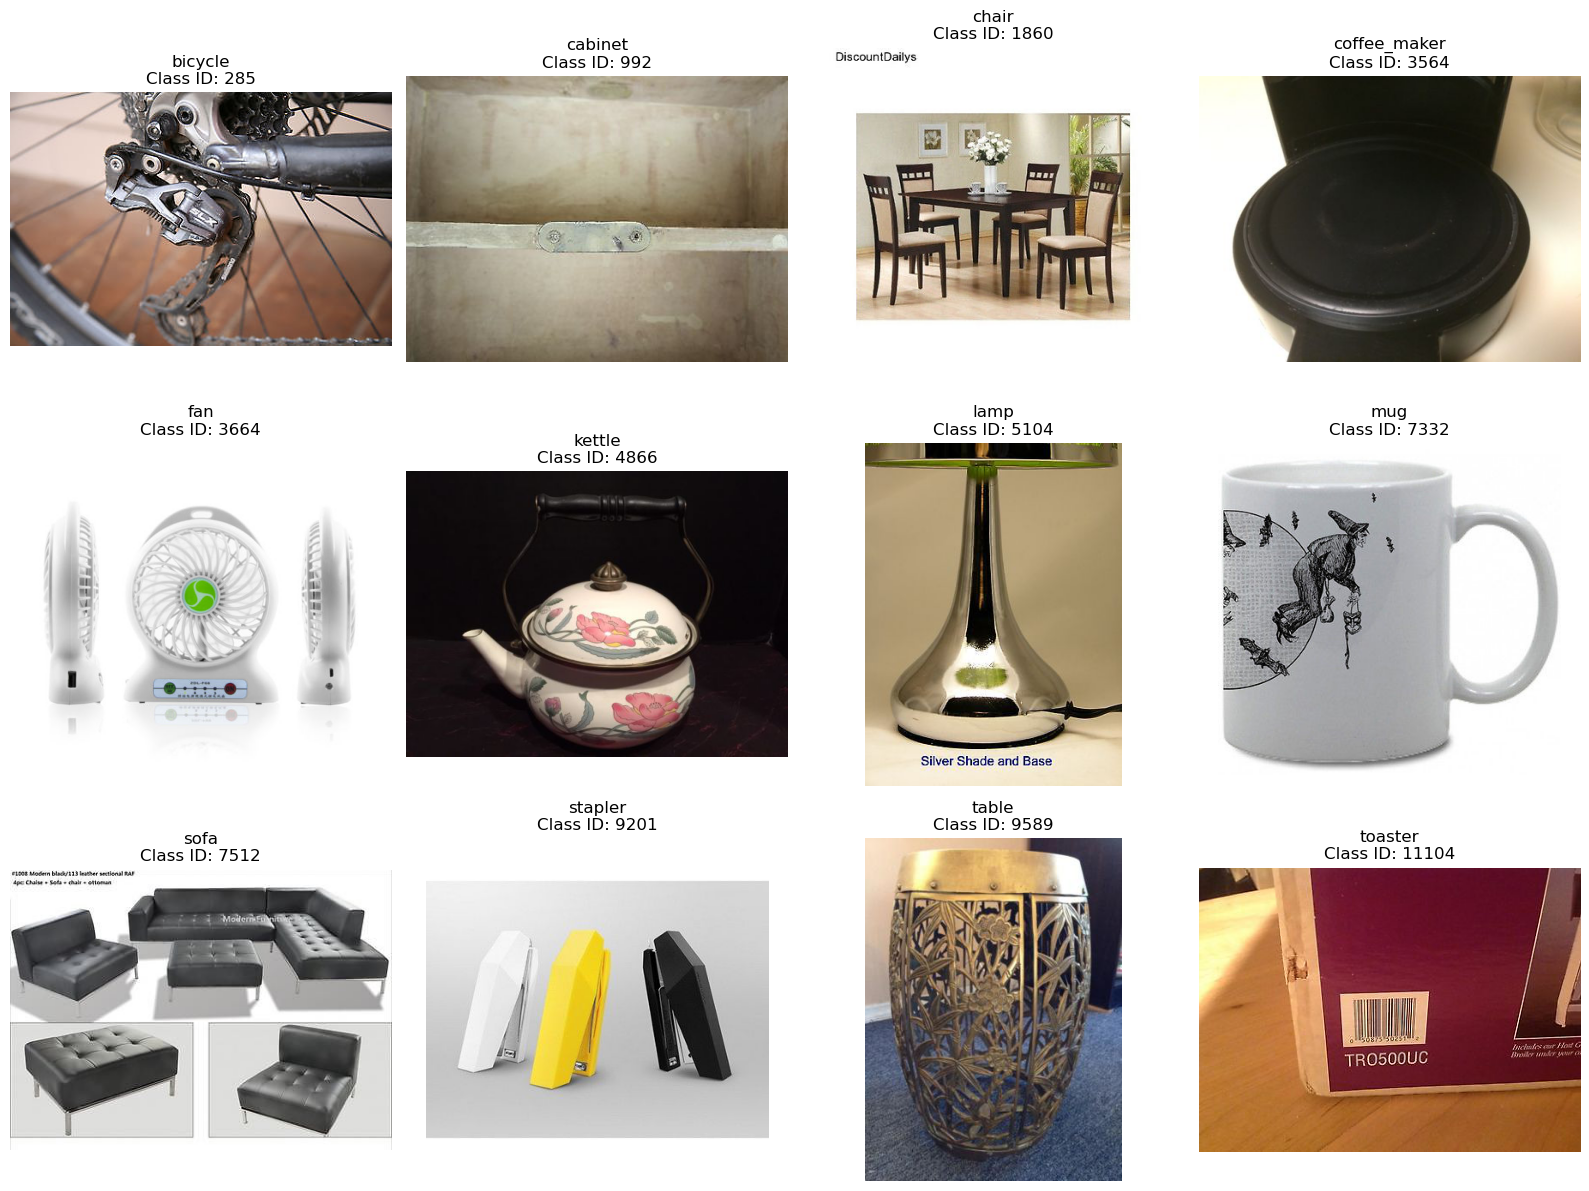

In [26]:
import matplotlib.pyplot as plt
from PIL import Image

category_samples = (
    train_metadata
    .groupby("category_name", group_keys=False)
    .sample(n=1, random_state=42)
    .sort_values("super_class_id")
)

plt.figure(figsize=(16, 12))

for position, (_, row) in enumerate(
    category_samples.iterrows(),
    start=1
):
    with Image.open(row["full_path"]) as image:
        plt.subplot(3, 4, position)
        plt.imshow(image)
        plt.title(
            f"{row['category_name']}\n"
            f"Class ID: {row['class_id']}"
        )
        plt.axis("off")

plt.tight_layout()
plt.show()

In [27]:
suspicious_class_id = 11104

same_product_images = train_metadata[
    train_metadata["class_id"] == suspicious_class_id
]

print("Number of images:", len(same_product_images))
same_product_images[["image_id", "class_id", "category_name", "path"]]

Number of images: 8


,image_id,class_id,category_name,path
58489,58490,11104,toaster,toaster_final/181833747771_0.JPG
58490,58491,11104,toaster,toaster_final/181833747771_1.JPG
58491,58492,11104,toaster,toaster_final/181833747771_2.JPG
58492,58493,11104,toaster,toaster_final/181833747771_3.JPG
58493,58494,11104,toaster,toaster_final/181833747771_4.JPG
58494,58495,11104,toaster,toaster_final/181833747771_5.JPG
58495,58496,11104,toaster,toaster_final/181833747771_6.JPG
58496,58497,11104,toaster,toaster_final/181833747771_7.JPG


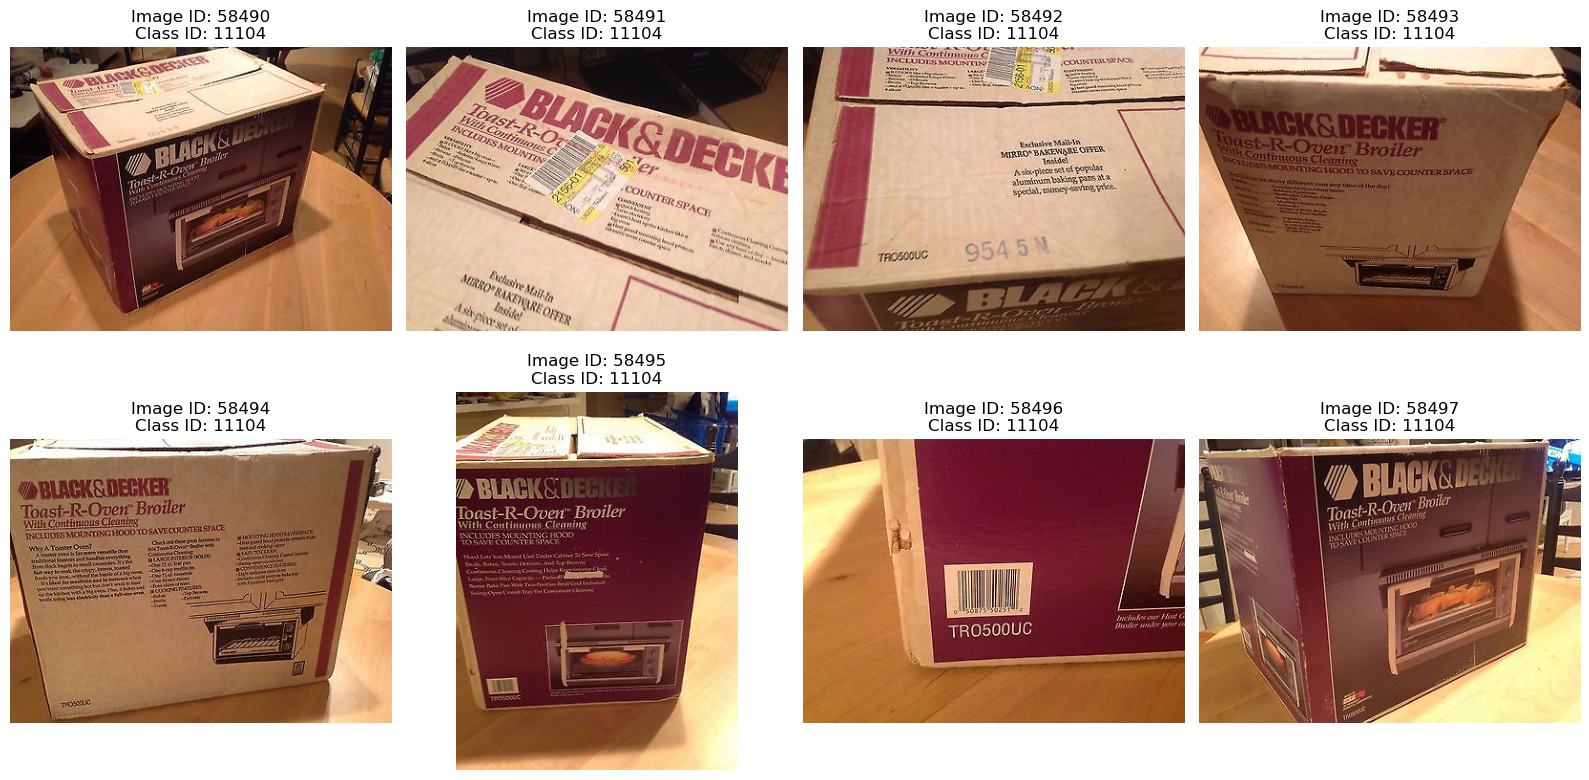

In [28]:
import matplotlib.pyplot as plt
from PIL import Image

number_of_images = len(same_product_images)

plt.figure(figsize=(16, 8))

for position, (_, row) in enumerate(
    same_product_images.iterrows(),
    start=1
):
    with Image.open(row["full_path"]) as image:
        plt.subplot(2, 4, position)
        plt.imshow(image)

    plt.title(
        f"Image ID: {row['image_id']}\n"
        f"Class ID: {row['class_id']}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [29]:
from PIL import Image, UnidentifiedImageError
from tqdm.auto import tqdm

image_checks = []

for _, row in tqdm(
    train_metadata.iterrows(),
    total=len(train_metadata),
    desc="Checking images"
):
    image_path = row["full_path"]

    try:
        with Image.open(image_path) as image:
            image_checks.append(
                {
                    "image_id": row["image_id"],
                    "class_id": row["class_id"],
                    "super_class_id": row["super_class_id"],
                    "category_name": row["category_name"],
                    "path": row["path"],
                    "width": image.width,
                    "height": image.height,
                    "mode": image.mode,
                    "format": image.format,
                    "is_corrupted": False
                }
            )

    except (UnidentifiedImageError, OSError, ValueError):
        image_checks.append(
            {
                "image_id": row["image_id"],
                "class_id": row["class_id"],
                "super_class_id": row["super_class_id"],
                "category_name": row["category_name"],
                "path": row["path"],
                "width": None,
                "height": None,
                "mode": None,
                "format": None,
                "is_corrupted": True
            }
        )

Checking images:   0%|          | 0/59551 [00:00<?, ?it/s]

In [30]:
image_checks_df = pd.DataFrame(image_checks)

image_checks_df.head()

,image_id,class_id,super_class_id,category_name,path,width,height,mode,format,is_corrupted
0,1,1,1,bicycle,bicycle_final/111085122871_0.JPG,400,268,RGB,JPEG,False
1,2,1,1,bicycle,bicycle_final/111085122871_1.JPG,400,268,RGB,JPEG,False
2,3,1,1,bicycle,bicycle_final/111085122871_2.JPG,400,268,RGB,JPEG,False
3,4,1,1,bicycle,bicycle_final/111085122871_3.JPG,400,268,RGB,JPEG,False
4,5,1,1,bicycle,bicycle_final/111085122871_4.JPG,400,268,RGB,JPEG,False


In [31]:
print("Total images checked:", len(image_checks_df))
print("Corrupted images:", image_checks_df["is_corrupted"].sum())

print("\nImage formats:")
print(image_checks_df["format"].value_counts(dropna=False))

print("\nImage modes:")
print(image_checks_df["mode"].value_counts(dropna=False))

Total images checked: 59551
Corrupted images: 0

Image formats:
format
JPEG    59551
Name: count, dtype: int64

Image modes:
mode
RGB    59263
L        288
Name: count, dtype: int64


In [32]:
image_checks_df[["width", "height"]].describe()

,width,height
count,59551.000000,59551.000000
mean,400.467633,372.878927
std,172.542374,141.009520
min,80.000000,67.000000
25%,375.000000,300.000000
50%,400.000000,400.000000
75%,400.000000,400.000000
max,5162.000000,3600.000000


In [33]:
small_images = image_checks_df[
    (image_checks_df["width"] < 150)
    | (image_checks_df["height"] < 150)
]

print("Images with width or height below 150 pixels:", len(small_images))

small_images[
    [
        "image_id",
        "class_id",
        "category_name",
        "width",
        "height",
        "path"
    ]
].head(10)

Images with width or height below 150 pixels: 192


,image_id,class_id,category_name,width,height,path
96,97,17,bicycle,400,142,bicycle_final/111646738161_9.JPG
1229,1230,190,bicycle,134,400,bicycle_final/141592798688_2.JPG
1423,1424,212,bicycle,400,100,bicycle_final/141731113810_7.JPG
1450,1451,215,bicycle,400,134,bicycle_final/141732891951_11.JPG
1940,1941,284,bicycle,80,80,bicycle_final/161749358291_0.JPG
4057,4058,556,bicycle,142,400,bicycle_final/231640728072_4.JPG
4155,4156,573,bicycle,400,146,bicycle_final/251921497784_1.JPG
4292,4293,605,cabinet,84,400,cabinet_final/111669658275_1.JPG
4522,4523,643,cabinet,133,400,cabinet_final/111734209286_0.JPG
4731,4732,678,cabinet,126,400,cabinet_final/121630311401_0.JPG


In [34]:
print("Total unusually small images:", len(small_images))

Total unusually small images: 192


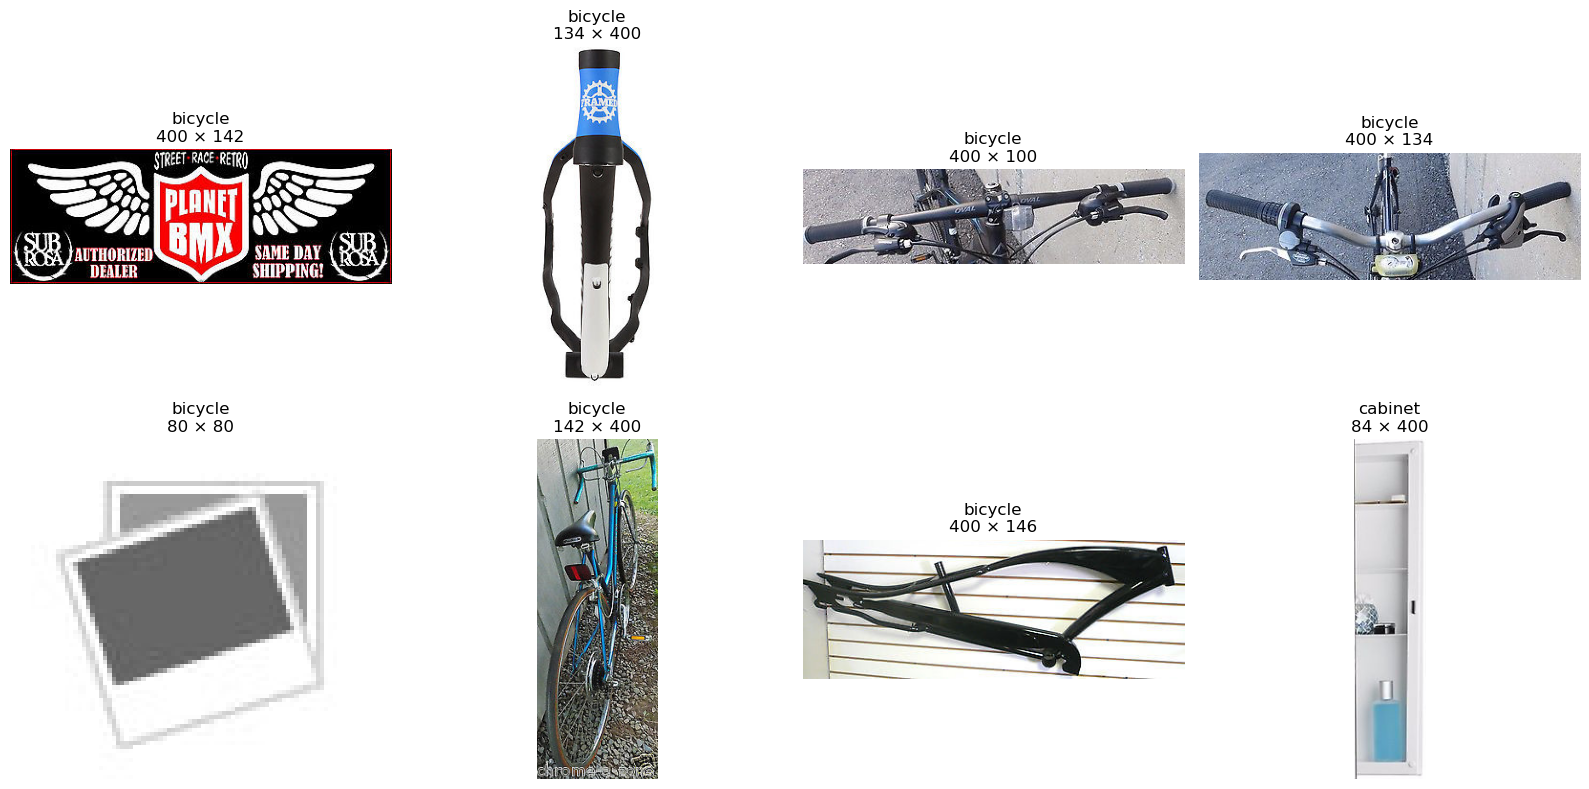

In [36]:
import matplotlib.pyplot as plt
from PIL import Image

small_sample = small_images.head(8)

plt.figure(figsize=(16, 8))

for position, (_, row) in enumerate(
    small_sample.iterrows(),
    start=1
):
    with Image.open(dataset_root / row["path"]) as image:
        plt.subplot(2, 4, position)
        plt.imshow(image)

    plt.title(
        f"{row['category_name']}\n"
        f"{row['width']} × {row['height']}"
    )
    plt.axis("off")

plt.tight_layout()
plt.show()

In [37]:
train_metadata_with_checks = train_metadata.merge(
    image_checks_df[
        [
            "image_id",
            "width",
            "height",
            "mode",
            "format",
            "is_corrupted"
        ]
    ],
    on="image_id",
    how="left"
)

train_metadata_with_checks.head()

,image_id,class_id,super_class_id,path,category_name,full_path,image_exists,width,height,mode,format,is_corrupted
0,1,1,1,bicycle_final/111085122871_0.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,268,RGB,JPEG,False
1,2,1,1,bicycle_final/111085122871_1.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,268,RGB,JPEG,False
2,3,1,1,bicycle_final/111085122871_2.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,268,RGB,JPEG,False
3,4,1,1,bicycle_final/111085122871_3.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,268,RGB,JPEG,False
4,5,1,1,bicycle_final/111085122871_4.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,268,RGB,JPEG,False


In [38]:
print("Rows before merge:", len(train_metadata))
print("Rows after merge:", len(train_metadata_with_checks))

print(
    "Missing width values:",
    train_metadata_with_checks["width"].isna().sum()
)

print(
    "Missing height values:",
    train_metadata_with_checks["height"].isna().sum()
)

Rows before merge: 59551
Rows after merge: 59551
Missing width values: 0
Missing height values: 0


In [39]:
class_summary = (
    train_metadata_with_checks
    .groupby(
        [
            "class_id",
            "super_class_id",
            "category_name"
        ]
    )
    .agg(
        image_count=("image_id", "count"),
        min_width=("width", "min"),
        min_height=("height", "min"),
        grayscale_count=("mode", lambda values: (values == "L").sum())
    )
    .reset_index()
)

class_summary["has_very_small_image"] = (
    (class_summary["min_width"] < 100)
    | (class_summary["min_height"] < 100)
)

class_summary.head()

,class_id,super_class_id,category_name,image_count,min_width,min_height,grayscale_count,has_very_small_image
0,1,1,bicycle,8,400,268,0,False
1,2,1,bicycle,7,400,268,0,False
2,3,1,bicycle,5,400,268,0,False
3,4,1,bicycle,9,400,240,0,False
4,5,1,bicycle,2,400,400,0,False


In [40]:
print("Total product classes:", len(class_summary))
print(class_summary["image_count"].describe())
print(
    "\nClasses containing a very small image:",
    class_summary["has_very_small_image"].sum()
)
print(
    "Classes containing grayscale images:",
    (class_summary["grayscale_count"] > 0).sum()
)

Total product classes: 11318
count    11318.000000
mean         5.261619
std          2.978530
min          2.000000
25%          3.000000
50%          4.000000
75%          7.000000
max         12.000000
Name: image_count, dtype: float64

Classes containing a very small image: 11
Classes containing grayscale images: 160


In [41]:
eligible_classes = class_summary[
    (class_summary["image_count"].between(4, 7))
    & (~class_summary["has_very_small_image"])
].copy()

print("Total eligible product classes:", len(eligible_classes))

eligible_by_category = (
    eligible_classes
    .groupby(["super_class_id", "category_name"])
    .agg(
        eligible_classes=("class_id", "count"),
        expected_images=("image_count", "sum")
    )
    .reset_index()
)

eligible_by_category

Total eligible product classes: 4850


,super_class_id,category_name,eligible_classes,expected_images
0,1,bicycle,194,1017
1,2,cabinet,333,1688
2,3,chair,471,2395
3,4,coffee_maker,381,2006
4,5,fan,223,1172
5,6,kettle,446,2344
6,7,lamp,488,2536
7,8,mug,759,3935
8,9,sofa,317,1586
9,10,stapler,416,2147


In [42]:
selected_classes = (
    eligible_classes
    .groupby("super_class_id", group_keys=False)
    .sample(n=50, random_state=42)
    .sort_values(
        ["super_class_id", "class_id"]
    )
    .reset_index(drop=True)
)

print("Selected product classes:", len(selected_classes))

selected_classes.head()

Selected product classes: 600


,class_id,super_class_id,category_name,image_count,min_width,min_height,grayscale_count,has_very_small_image
0,16,1,bicycle,4,400,400,0,False
1,25,1,bicycle,4,311,348,0,False
2,31,1,bicycle,4,400,400,0,False
3,32,1,bicycle,4,400,400,0,False
4,34,1,bicycle,4,400,241,0,False


In [43]:
selected_class_distribution = (
    selected_classes
    .groupby(["super_class_id", "category_name"])
    .agg(
        selected_classes=("class_id", "count"),
        expected_images=("image_count", "sum")
    )
    .reset_index()
)

selected_class_distribution

,super_class_id,category_name,selected_classes,expected_images
0,1,bicycle,50,250
1,2,cabinet,50,265
2,3,chair,50,263
3,4,coffee_maker,50,260
4,5,fan,50,244
5,6,kettle,50,259
6,7,lamp,50,262
7,8,mug,50,264
8,9,sofa,50,260
9,10,stapler,50,263


In [44]:
print(
    "Total selected product classes:",
    selected_classes["class_id"].nunique()
)

print(
    "Expected total images:",
    selected_classes["image_count"].sum()
)

Total selected product classes: 600
Expected total images: 3095


In [45]:
selected_class_ids = selected_classes["class_id"]

final_metadata = (
    train_metadata_with_checks[
        train_metadata_with_checks["class_id"].isin(
            selected_class_ids
        )
    ]
    .copy()
    .sort_values(
        [
            "super_class_id",
            "class_id",
            "image_id"
        ]
    )
    .reset_index(drop=True)
)

print("Final image count:", len(final_metadata))
print(
    "Final product classes:",
    final_metadata["class_id"].nunique()
)
print(
    "Final categories:",
    final_metadata["super_class_id"].nunique()
)

final_metadata.head()

Final image count: 3095
Final product classes: 600
Final categories: 12


,image_id,class_id,super_class_id,path,category_name,full_path,image_exists,width,height,mode,format,is_corrupted
0,84,16,1,bicycle_final/111645993618_0.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
1,85,16,1,bicycle_final/111645993618_1.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
2,86,16,1,bicycle_final/111645993618_2.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
3,87,16,1,bicycle_final/111645993618_3.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False
4,129,25,1,bicycle_final/111688507119_0.JPG,bicycle,c:\Users\hunte\VS Code\Visual Product Similari...,True,400,400,RGB,JPEG,False


In [51]:
processed_data_dir = project_root / "data" / "processed"

In [52]:
final_metadata_path = (
    processed_data_dir
    / "selected_product_metadata.csv"
)

final_metadata.to_csv(
    final_metadata_path,
    index=False
)

print("Metadata saved to:", final_metadata_path)
print("File exists:", final_metadata_path.exists())

Metadata saved to: c:\Users\hunte\VS Code\Visual Product Similarity\data\processed\selected_product_metadata.csv
File exists: True
